# Idea 8 - Polanyi's Paradox and the Moving Frontier

**The claim (Machines, Platforms, Crowds, ch. 1-3).** We know more than we can
tell. A large share of human competence is tacit: we execute it fluently and
cannot state the rules. Autor's economic formulation, which the notes quote
twice, is that substituting computers for people is "bounded because there are
many tasks that people understand tacitly and accomplish effortlessly but for
which neither computer programmers nor anyone else can enunciate the explicit
rules or procedures."

The book's argument is that machine learning dissolves the bound by changing
what has to be specified. Instead of the rules, you supply the goal and the
examples. The notes call this "the hinge on which the first five chapters
turn": the boundary of automation is no longer the boundary of what humans can
explain.

**What that predicts, and how to test it.** Polanyi's paradox and Moravec's
paradox together make a specific prediction about which jobs disappear. Work
whose rules can be written down should be automated first. Work that is tacit,
perceptual or manual should be safe, because nobody can specify it. If the book
is right that the bound is dissolving, the second category should stop being
safe.

So the test is the composition of American employment, sorted by how
codifiable the work is:

1. Does employment fall where the rules can be written down?
2. Does it hold up where the work is tacit, as Polanyi predicts?
3. Has the frontier moved, comparing the years before and after deep learning
   became practical?
4. Do wages tell the same story as headcount, or a different one?
5. Which occupations actually shrank, named rather than aggregated?

**The judgement this notebook makes openly.** Testing Polanyi needs a measure
of how tacit each occupation is. The standard source is O*NET's task ratings,
whose bulk files require guessing version-specific download URLs, which is the
practice that produced a mislabelled figure in Idea 5. Instead this notebook
writes out its own classification of occupation groups into Autor's routine and
non-routine, cognitive and manual quadrants, prints it in full, and invites
disagreement. It is a judgement, disclosed, in the same way Idea 6 disclosed the
proprietors' income assumption. Anyone who disputes a cell can move it and
rerun.

**Data.** Census ACS occupation tables, retrieved with variable labels from the
API's own metadata endpoint rather than by assuming variable numbers.

In [1]:
import sys, pathlib, warnings, importlib, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

_here = pathlib.Path.cwd()
for _cand in [_here, *_here.parents]:
    if (_cand / "common" / "stacklib.py").exists():
        sys.path.insert(0, str(_cand / "common"))
        break
import stacklib as sl
importlib.reload(sl)

warnings.filterwarnings("ignore", category=FutureWarning)
print("stacklib version:", sl.__version__)
assert sl.__version__ >= "0.8.0", "needs stacklib 0.8.0 for census_group_labels"

DIRS = sl.dirs_for("08_polanyis_paradox")
KEYS = sl.load_keys()
sl.apply_theme()
CENSUS = sl.require(KEYS, "CENSUS")

ACS = "https://api.census.gov/data/%d/acs/acs1"
YEARS = [y for y in range(2010, 2024) if y != 2020]     # no ACS 1-year for 2020
EARLY, LATE = (2010, 2014), (2019, 2023)                # before and after deep learning

stacklib version: 0.8.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED


## 1. Read the occupation tree from the source

Census labels encode a hierarchy with "!!" separators. Printing that tree is
how we choose a level of detail deliberately instead of guessing which variable
numbers mean what.

In [2]:
GROUP = "C24010"          # sex by occupation, collapsed; B24010 is the detailed version
labels = sl.census_group_labels(ACS % 2023, GROUP)
print()
for d in sorted(labels["depth"].unique()):
    n = (labels["depth"] == d).sum()
    sample = labels[labels["depth"] == d]["leaf"].head(3).tolist()
    print("  depth %d: %3d variables   e.g. %s" % (d, n, sample))

Census C24010: 74 estimate variables, depths [1, 2, 3, 4, 5, 6]

  depth 1:   1 variables   e.g. ['Geographic Area Name']
  depth 2:   1 variables   e.g. ['Total']
  depth 3:   2 variables   e.g. ['Male', 'Female']
  depth 4:  10 variables   e.g. ['Management, business, science, and arts occupations', 'Service occupations', 'Sales and office occupations']
  depth 5:  34 variables   e.g. ['Management, business, and financial occupations', 'Computer, engineering, and science occupations', 'Education, legal, community service, arts, and media occupations']
  depth 6:  26 variables   e.g. ['Management occupations', 'Business and financial operations occupations', 'Computer and mathematical occupations']


In [3]:
# Depth 3 is "Estimate!!Total!!Male/Female"; depth 4 is the major occupation
# groups within sex; depth 5 is the minor groups. We want minor groups summed
# across sex, which is the finest level this table offers.
DEPTH = 5
minor = labels[labels["depth"] == DEPTH].copy()
minor["group"] = minor["leaf"]
print("%d variables at depth %d, covering %d distinct occupation groups"
      % (len(minor), DEPTH, minor["group"].nunique()))
print()
for g in sorted(minor["group"].unique()):
    print("   -", g)

34 variables at depth 5, covering 17 distinct occupation groups

   - Building and grounds cleaning and maintenance occupations
   - Computer, engineering, and science occupations
   - Construction and extraction occupations
   - Education, legal, community service, arts, and media occupations
   - Farming, fishing, and forestry occupations
   - Food preparation and serving related occupations
   - Healthcare practitioners and technical occupations
   - Healthcare support occupations
   - Installation, maintenance, and repair occupations
   - Management, business, and financial occupations
   - Material moving occupations
   - Office and administrative support occupations
   - Personal care and service occupations
   - Production occupations
   - Protective service occupations
   - Sales and related occupations
   - Transportation occupations


## 2. The classification, written out

Autor's two-by-two. **Routine** means the task can be stated as a procedure,
which is what Polanyi says most human competence cannot be. **Cognitive** and
**manual** separate desk work from physical work, which is the axis Moravec's
paradox runs along.

The predictions being tested:

* Routine cognitive should be automated first: the rules are writable.
* Routine manual should follow, since industrial machinery predates computing.
* Non-routine manual is Moravec's protected zone: easy for a toddler,
  historically impossible for a machine.
* Non-routine cognitive is Polanyi's protected zone: judgement nobody can spell out.

The book's claim is that machine learning is now eating into the two protected
zones. Disagree with any assignment below by editing the dictionary and
rerunning; that is the point of printing it.

In [5]:
# Autor's two-by-two, expressed as ordered keyword rules rather than exact strings.
# ACS occupation wording differs by table, by depth and by year, so matching whole
# labels is brittle. First rule that matches wins, and the resolution is printed
# in full so every assignment can be checked and argued with.
RULES = [
    # --- Routine cognitive: procedural desk work, rules writable ----------------
    (r"office and administrative",              "Routine cognitive"),
    (r"^sales",                                 "Routine cognitive"),
    (r"^business and financial",                "Routine cognitive"),
    # --- Non-routine cognitive: Polanyi's zone, judgement and persuasion --------
    (r"management, business, and financial",    "Non-routine cognitive"),  # lumped, see note
    (r"^management",                            "Non-routine cognitive"),
    (r"computer|mathematical",                  "Non-routine cognitive"),
    (r"architecture|engineering, and science",  "Non-routine cognitive"),
    (r"life, physical, and social science",     "Non-routine cognitive"),
    (r"education|legal|community and social",   "Non-routine cognitive"),
    (r"arts, design",                           "Non-routine cognitive"),
    (r"healthcare practitioners|health diagnosing|health technologists",
                                                "Non-routine cognitive"),
    # --- Non-routine manual: Moravec's zone, perception and dexterity -----------
    (r"healthcare support",                     "Non-routine manual"),
    (r"protective service|fire fighting|law enforcement", "Non-routine manual"),
    (r"food preparation",                       "Non-routine manual"),
    (r"building and grounds",                   "Non-routine manual"),
    (r"personal care",                          "Non-routine manual"),
    (r"installation, maintenance, and repair",  "Non-routine manual"),
    # --- Routine manual: repetitive physical work ------------------------------
    (r"farming|fishing|forestry",               "Routine manual"),
    (r"construction and extraction",            "Routine manual"),
    (r"^production",                            "Routine manual"),
    (r"transportation|material moving",         "Routine manual"),
]
ORDER = ["Routine cognitive", "Routine manual", "Non-routine manual", "Non-routine cognitive"]

def classify(group):
    g = group.lower().strip()
    for pattern, quadrant in RULES:
        if re.search(pattern, g):
            return quadrant, pattern
    return None, None

observed = sorted(minor["group"].unique())
QUADRANT, audit, unmapped = {}, [], []
for g in observed:
    q, rule = classify(g)
    if q is None:
        unmapped.append(g)
    else:
        QUADRANT[g] = q
        audit.append({"occupation group": g, "quadrant": q, "matched rule": rule})

print("RESOLUTION (%d groups). Check every row; edit RULES to disagree.\n" % len(audit))
print(pd.DataFrame(audit).to_string(index=False))

if unmapped:
    print("\nUNCLASSIFIED (%d):" % len(unmapped))
    for g in unmapped:
        print("   -", g)
    raise AssertionError(
        "Every occupation group must be classified or the shares will not sum to one. "
        "Add a rule to RULES for each group listed above and rerun.")

print("\nquadrant sizes:", {q: sum(v == q for v in QUADRANT.values()) for q in ORDER})

RESOLUTION (17 groups). Check every row; edit RULES to disagree.

                                                occupation group              quadrant                                                    matched rule
       Building and grounds cleaning and maintenance occupations    Non-routine manual                                            building and grounds
                  Computer, engineering, and science occupations Non-routine cognitive                                           computer|mathematical
                         Construction and extraction occupations        Routine manual                                     construction and extraction
Education, legal, community service, arts, and media occupations Non-routine cognitive                            education|legal|community and social
                      Farming, fishing, and forestry occupations        Routine manual                                        farming|fishing|forestry
                Food prepara

## 3. Pull employment by occupation

One call per year. Variables are selected by the labels fetched above, never by
assumed variable numbers.

In [6]:
var_list = minor["name"].tolist()
def fetch_year(year):
    got = sl.census_timeseries(ACS % year, {"get": "group(%s)" % GROUP, "for": "us:1"},
                               CENSUS, cache_dir=DIRS["data"], tag="%s_%d" % (GROUP.lower(), year))
    row = got.iloc[0]
    out = {}
    for _, r in minor.iterrows():
        if r["name"] in got.columns:
            out.setdefault(r["group"], 0.0)
            out[r["group"]] += float(row[r["name"]])
    return out

emp = {}
for y in YEARS:
    try:
        emp[y] = fetch_year(y)
    except Exception as e:
        print("  %d unavailable (%s)" % (y, str(e)[:70]))

E = pd.DataFrame(emp).T.sort_index()
E.index = E.index.astype(int)
print("\nemployment by occupation group, millions:")
print((E[[c for c in E.columns[:4]]] / 1e6).round(2).to_string())

total = E.sum(axis=1)
print("\ntotal employed, millions: %.1f (%d) -> %.1f (%d)"
      % (total.iloc[0]/1e6, total.index[0], total.iloc[-1]/1e6, total.index[-1]))

Census c24010_2010: 1 rows
Census c24010_2011: 1 rows
Census c24010_2012: 1 rows
Census c24010_2013: 1 rows
Census c24010_2014: 1 rows
Census c24010_2015: 1 rows
Census c24010_2016: 1 rows
Census c24010_2017: 1 rows
Census c24010_2018: 1 rows
Census c24010_2019: 1 rows
Census c24010_2021: 1 rows
Census c24010_2022: 1 rows
Census c24010_2023: 1 rows

employment by occupation group, millions:
      Management, business, and financial occupations  Computer, engineering, and science occupations  Education, legal, community service, arts, and media occupations  Healthcare practitioners and technical occupations
2010                                            19.97                                            7.16                                                             15.21                                                7.63
2011                                            20.10                                            7.36                                                             15.1

## Figure 1 - Employment by task type

Shares of total employment, so the four quadrants sum to one and the question
is composition rather than the business cycle.

saved -> C:\Users\91838\Downloads\Stack_Article\08_polanyis_paradox\figures\fig1_quadrant_shares.png


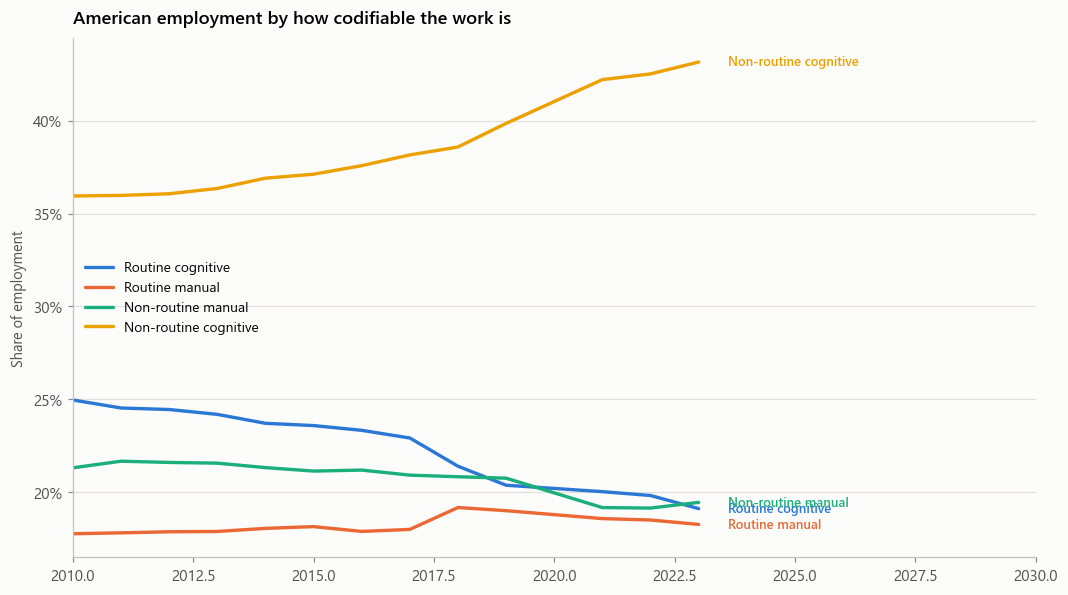

      Routine cognitive  Routine manual  Non-routine manual  Non-routine cognitive
2010              24.97           17.77               21.32                  35.94
2011              24.54           17.82               21.67                  35.98
2012              24.45           17.88               21.61                  36.06
2013              24.19           17.89               21.57                  36.35
2014              23.71           18.06               21.33                  36.90
2015              23.59           18.15               21.14                  37.12
2016              23.33           17.89               21.19                  37.58
2017              22.92           18.00               20.92                  38.15
2018              21.40           19.18               20.84                  38.58
2019              20.38           19.01               20.76                  39.85
2021              20.03           18.58               19.18                  42.21
2022

In [7]:
Q = pd.DataFrame({q: E[[c for c in E.columns if QUADRANT[c] == q]].sum(axis=1)
                  for q in ORDER})
Qs = Q.div(Q.sum(axis=1), axis=0) * 100
assert abs(Qs.sum(axis=1) - 100).max() < 1e-6, "shares must sum to 100"

fig, ax = plt.subplots(figsize=(9.6, 5.3))
for q, color in zip(ORDER, sl.PALETTE[:4]):
    ax.plot(Qs.index, Qs[q].values, color=color, lw=2.2, label=q)
    sl.label_last(ax, Qs[q], q, color, fontsize=8.5)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%.0f%%" % v))
ax.set_ylabel("Share of employment")
ax.set_xlim(Qs.index.min(), Qs.index.max() + 7)
ax.set_title("American employment by how codifiable the work is")
ax.legend(loc="center left")
sl.save_fig(fig, "fig1_quadrant_shares", DIRS)
plt.show()
print(Qs.round(2).to_string())

## Figure 2 - Did the frontier move?

Average annual change in each quadrant's employment share, comparing the early
window with the late one. Polanyi's prediction is that the non-routine bars
stay flat or positive. The book's claim is that they turn down in the later
period.

saved -> C:\Users\91838\Downloads\Stack_Article\08_polanyis_paradox\figures\fig2_frontier_shift.png


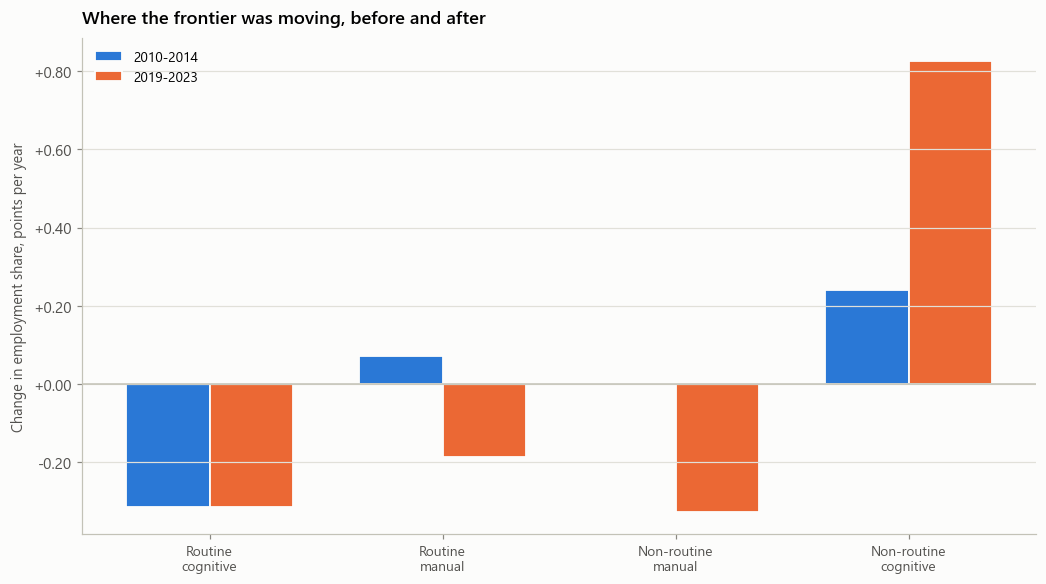

                       2010-2014  2019-2023
Routine cognitive         -0.314     -0.315
Routine manual             0.072     -0.185
Non-routine manual         0.002     -0.326
Non-routine cognitive      0.239      0.825


In [8]:
def window_rate(df, lo, hi):
    w = df[(df.index >= lo) & (df.index <= hi)]
    return (w.iloc[-1] - w.iloc[0]) / (w.index[-1] - w.index[0])

early = window_rate(Qs, *EARLY)
late = window_rate(Qs, *LATE)
comp = pd.DataFrame({"%d-%d" % EARLY: early, "%d-%d" % LATE: late}).loc[ORDER]

fig, ax = plt.subplots(figsize=(9.4, 5.2))
idx = np.arange(len(ORDER)); w = 0.36
ax.bar(idx - w/2, comp.iloc[:, 0].values, width=w, color=sl.PALETTE[0],
       edgecolor=sl.INK["surface"], linewidth=1.2, label=comp.columns[0])
ax.bar(idx + w/2, comp.iloc[:, 1].values, width=w, color=sl.PALETTE[1],
       edgecolor=sl.INK["surface"], linewidth=1.2, label=comp.columns[1])
ax.axhline(0, color=sl.INK["axis"], lw=1.0)
ax.set_xticks(idx); ax.set_xticklabels([q.replace(" ", "\n", 1) for q in ORDER], fontsize=9)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%+.2f" % v))
ax.set_ylabel("Change in employment share, points per year")
ax.set_title("Where the frontier was moving, before and after")
ax.legend(loc="best")
sl.save_fig(fig, "fig2_frontier_shift", DIRS)
plt.show()
print(comp.round(3).to_string())

## Figure 3 - Which occupations actually shrank

The quadrants are an interpretation. The occupation groups underneath them are
data. This ranks them by change in employment share so the reader can check the
classification against the outcome.

saved -> C:\Users\91838\Downloads\Stack_Article\08_polanyis_paradox\figures\fig3_occupation_ranking.png


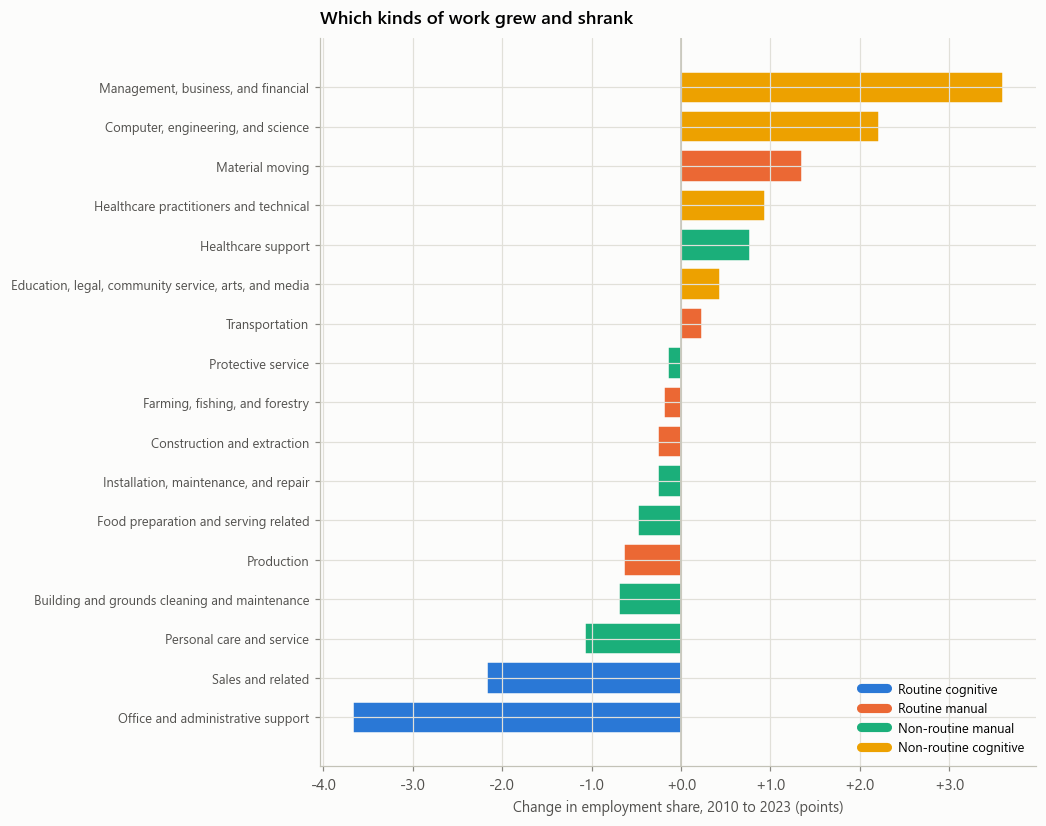

Office and administrative support occupations                      -3.674
Sales and related occupations                                      -2.171
Personal care and service occupations                              -1.070
Building and grounds cleaning and maintenance occupations          -0.696
Production occupations                                             -0.641
Food preparation and serving related occupations                   -0.475
Installation, maintenance, and repair occupations                  -0.257
Construction and extraction occupations                            -0.255
Farming, fishing, and forestry occupations                         -0.193
Protective service occupations                                     -0.144
Transportation occupations                                          0.233
Education, legal, community service, arts, and media occupations    0.443
Healthcare support occupations                                      0.779
Healthcare practitioners and technical

In [9]:
share = E.div(E.sum(axis=1), axis=0) * 100
chg = (share.loc[share.index.max()] - share.loc[share.index.min()]).sort_values()
colors = [sl.PALETTE[ORDER.index(QUADRANT[g]) % 4] for g in chg.index]

fig, ax = plt.subplots(figsize=(9.4, 7.4))
ax.barh(range(len(chg)), chg.values, color=colors,
        edgecolor=sl.INK["surface"], linewidth=1.0)
ax.set_yticks(range(len(chg)))
ax.set_yticklabels([g.replace(" occupations", "") for g in chg.index], fontsize=8.5)
ax.axvline(0, color=sl.INK["axis"], lw=1.0)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: "%+.1f" % v))
ax.set_xlabel("Change in employment share, %d to %d (points)"
              % (share.index.min(), share.index.max()))
ax.set_title("Which kinds of work grew and shrank")
ax.grid(axis="x")
handles = [plt.Line2D([0], [0], color=sl.PALETTE[i], lw=6) for i in range(4)]
ax.legend(handles, ORDER, loc="lower right", fontsize=8.5)
sl.save_fig(fig, "fig3_occupation_ranking", DIRS)
plt.show()
print(chg.round(3).to_string())

## Figure 4 - Headcount against pay

Employment share is one signal and it is ambiguous: a shrinking occupation may
be automated or may simply be unfashionable. Median earnings are a second
signal. Work being replaced should lose both; work being complemented by
machines should shed workers while paying the survivors more.

Census B24011: 37 estimate variables, depths [1, 2, 3, 4, 5]
earnings variables matched to occupation groups: 17 of 17
Census b24011_2010: reading cache
  2010: 17 occupation groups with a positive median
Census b24011_2023: reading cache
  2023: 17 occupation groups with a positive median

17 occupation groups usable in both 2010 and 2023
saved -> C:\Users\91838\Downloads\Stack_Article\08_polanyis_paradox\figures\fig4_headcount_vs_pay.png


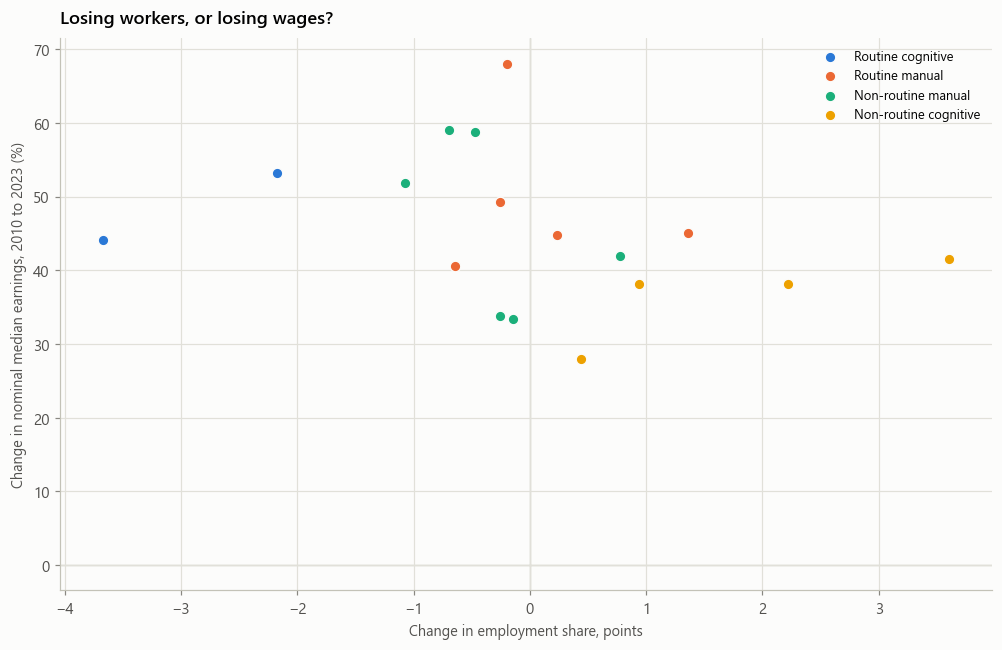

                                                                  earn_change_pct  share_change               quadrant
Building and grounds cleaning and maintenance occupations                   59.02         -0.70     Non-routine manual
Computer, engineering, and science occupations                              38.09          2.22  Non-routine cognitive
Construction and extraction occupations                                     49.27         -0.26         Routine manual
Education, legal, community service, arts, and media occupations            28.00          0.44  Non-routine cognitive
Farming, fishing, and forestry occupations                                  68.06         -0.19         Routine manual
Food preparation and serving related occupations                            58.83         -0.47     Non-routine manual
Healthcare practitioners and technical occupations                          38.17          0.94  Non-routine cognitive
Healthcare support occupations                  

In [11]:
# Median earnings by occupation. Match on the occupation name at whatever depth
# it appears, rather than assuming a depth: B24011 does not nest the same way
# C24010 does, and assuming it did is what emptied this join.
EARN_GROUP = "B24011"
earn, ew = {}, None
try:
    elabels = sl.census_group_labels(ACS % 2023, EARN_GROUP)

    # Drop the male/female branches; we want the combined figure.
    body = elabels[~elabels["label"].str.contains("Male|Female", case=False, na=False)].copy()
    wanted = set(chg.index)
    ekeep = body[body["leaf"].isin(wanted)].drop_duplicates(subset="leaf")
    print("earnings variables matched to occupation groups: %d of %d"
          % (len(ekeep), len(wanted)))

    if len(ekeep) < 4:
        print("\nToo few matched. Occupation names present in %s:" % EARN_GROUP)
        for leaf in sorted(body["leaf"].unique()):
            print("   -", leaf)
        raise LookupError("earnings labels do not line up with the occupation groups")

    for y in [share.index.min(), share.index.max()]:
        got = sl.census_timeseries(ACS % y, {"get": "group(%s)" % EARN_GROUP, "for": "us:1"},
                                   CENSUS, cache_dir=DIRS["data"],
                                   tag="%s_%d" % (EARN_GROUP.lower(), y))
        row = got.iloc[0]
        earn[y] = {r["leaf"]: float(row[r["name"]])
                   for _, r in ekeep.iterrows()
                   if r["name"] in got.columns
                   and pd.notna(row[r["name"]]) and float(row[r["name"]]) > 0}
        print("  %d: %d occupation groups with a positive median" % (y, len(earn[y])))
except Exception as e:
    print("earnings step skipped (%s)" % str(e)[:140])

if len(earn) == 2:
    y0, y1 = min(earn), max(earn)
    common = sorted(set(earn[y0]) & set(earn[y1]) & set(chg.index))
    print("\n%d occupation groups usable in both %d and %d" % (len(common), y0, y1))

if len(earn) == 2 and len(common) >= 4:
    ew = pd.DataFrame(
        {"earn_change_pct": [earn[y1][g] / earn[y0][g] * 100 - 100 for g in common],
         "share_change": [float(chg[g]) for g in common],
         "quadrant": [QUADRANT[g] for g in common]},
        index=common)

    fig, ax = plt.subplots(figsize=(9.0, 5.8))
    for q, color in zip(ORDER, sl.PALETTE[:4]):
        sub = ew.loc[ew["quadrant"] == q]      # boolean Series, never a bare list
        if sub.empty:
            continue
        ax.scatter(sub["share_change"], sub["earn_change_pct"], s=48, color=color,
                   edgecolors=sl.INK["surface"], linewidths=0.9, label=q, zorder=2)
    ax.axhline(0, color=sl.INK["axis"], lw=0.9, zorder=0)
    ax.axvline(0, color=sl.INK["axis"], lw=0.9, zorder=0)
    ax.set_xlabel("Change in employment share, points")
    ax.set_ylabel("Change in nominal median earnings, %d to %d (%%)" % (y0, y1))
    ax.set_title("Losing workers, or losing wages?")
    ax.legend(loc="best", fontsize=8.5)
    ax.grid(axis="x")
    sl.save_fig(fig, "fig4_headcount_vs_pay", DIRS)
    plt.show()
    print(ew.round(2).to_string())
else:
    ew = None
    print("Skipping Figure 4: earnings did not resolve for both endpoints "
          "with at least four shared occupation groups.")

## Figure 5 - The benchmark

Employment composition shifts for many reasons that have nothing to do with
automation: ageing, trade, the housing cycle, the pandemic. Before reading a
task story into Figure 2, ask how much of the movement a task classification
explains at all.

The test: shuffle the quadrant labels across occupation groups at random, many
times, and recompute the spread between quadrant trends. If the real spread
sits inside the distribution of random spreads, the classification is carrying
no information and the article should say so.

saved -> C:\Users\91838\Downloads\Stack_Article\08_polanyis_paradox\figures\fig5_permutation_benchmark.png


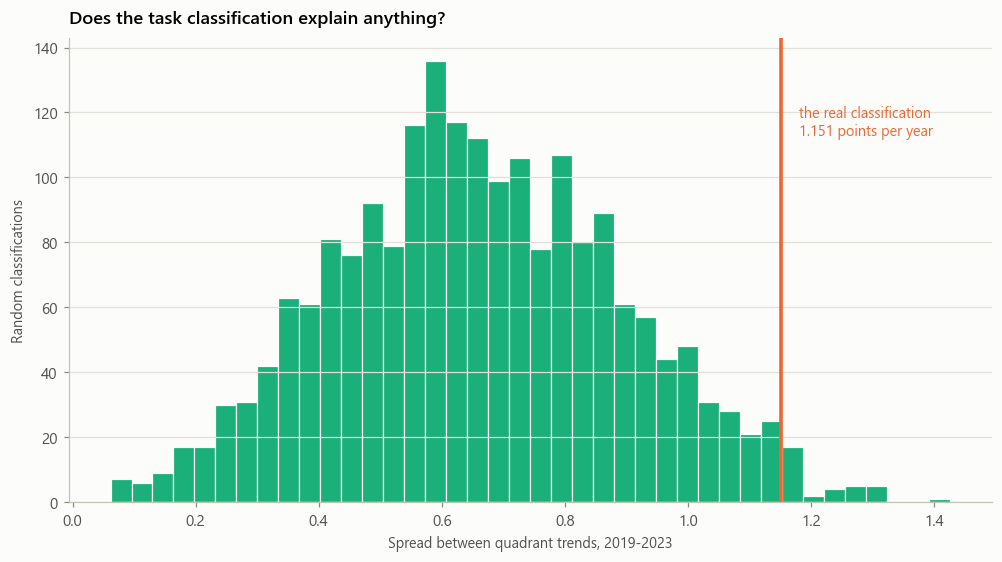

real spread 1.1511 points/year; 2000 random classifications; p = 0.018
VERDICT: the classification carries information


In [12]:
rng = np.random.default_rng(11)
real_spread = float(late.max() - late.min())
groups = list(chg.index)
sizes = share.loc[share.index.max()]

null_spreads = []
for _ in range(2000):
    perm = rng.permutation(groups)
    assign = {g: QUADRANT[p] for g, p in zip(groups, perm)}
    Qp = pd.DataFrame({q: E[[c for c in E.columns if assign[c] == q]].sum(axis=1)
                       for q in ORDER}).fillna(0.0)
    Qps = Qp.div(Qp.sum(axis=1), axis=0) * 100
    r = window_rate(Qps, *LATE)
    null_spreads.append(float(r.max() - r.min()))
null_spreads = np.array(null_spreads)
pval = float((null_spreads >= real_spread).mean())

fig, ax = plt.subplots(figsize=(9.0, 5.0))
ax.hist(null_spreads, bins=40, color=sl.PALETTE[2], edgecolor=sl.INK["surface"], linewidth=0.8)
ax.axvline(real_spread, color=sl.PALETTE[1], lw=2.4)
ax.annotate("the real classification\n%.3f points per year" % real_spread,
            xy=(real_spread, ax.get_ylim()[1]*0.82), xytext=(12, 0),
            textcoords="offset points", color=sl.PALETTE[1], fontsize=9.5, va="center")
ax.set_xlabel("Spread between quadrant trends, %d-%d" % LATE)
ax.set_ylabel("Random classifications")
ax.set_title("Does the task classification explain anything?")
sl.save_fig(fig, "fig5_permutation_benchmark", DIRS)
plt.show()
print("real spread %.4f points/year; %d random classifications; p = %.3f"
      % (real_spread, len(null_spreads), pval))
print("VERDICT:", "the classification carries information" if pval < 0.05
      else "the classification is NOT distinguishable from random labels")

## 4. Bank the numbers

In [13]:
payload = {
    "stacklib_version": sl.__version__,
    "acs_group": GROUP, "earnings_group": EARN_GROUP,
    "years": [int(y) for y in Qs.index],
    "quadrant_map": QUADRANT,
    "quadrant_shares_pct": Qs.round(3).to_dict(orient="index"),
    "quadrant_trend_points_per_year": {"early_window": list(EARLY), "late_window": list(LATE),
                                       "early": early.round(4).to_dict(),
                                       "late": late.round(4).to_dict()},
    "occupation_share_change_points": chg.round(3).to_dict(),
    "headcount_vs_pay": (None if ew is None else ew.round(3).to_dict(orient="index")),
    "permutation_test": {"real_spread": real_spread, "draws": len(null_spreads),
                         "p_value": pval,
                         "null_mean": float(null_spreads.mean()),
                         "null_95th": float(np.percentile(null_spreads, 95))},
}
sl.write_findings(payload, DIRS)
Qs.to_csv(pathlib.Path(DIRS["findings"]) / "quadrant_shares.csv")
chg.to_frame("share_change_points").to_csv(
    pathlib.Path(DIRS["findings"]) / "occupation_share_change.csv")
print("\nDone. Figures in figures/, numbers in findings/.")

findings -> C:\Users\91838\Downloads\Stack_Article\08_polanyis_paradox\findings\headline_numbers.json

Done. Figures in figures/, numbers in findings/.


## Caveats to carry into the prose

1. **The classification is a judgement, not a measurement.** Every assignment
   in QUADRANT was made by hand. The permutation test in Figure 5 is the check
   on whether it carries information; quote that verdict alongside any claim
   built on the quadrants.
2. **Occupations are not tasks.** Autor's own point is that automation replaces
   tasks within jobs, not whole jobs. An occupation can keep its headcount while
   most of its work changes, and this data cannot see that at all.
3. **Fourteen years is short and includes a pandemic.** The late window covers
   2019 to 2023, which contains the largest labour-market disruption in eighty
   years. Attributing its shape to machine learning requires an argument this
   notebook does not supply.
4. **Nominal earnings.** Figure 4 compares nominal medians across years, so
   every point is lifted by inflation. Only the relative positions mean anything.
5. **Composition, not level.** Shares can fall because one category shrinks or
   because others grow. Check the underlying counts before saying a kind of
   work is disappearing.

**Send back:** the five PNGs, the printed occupation tree, the unmapped-groups
check, the quadrant share table, the early-against-late comparison, the ranked
occupation table, and `findings/headline_numbers.json`. The permutation verdict
in Figure 5 decides how much of this the article can use.